<a href="https://colab.research.google.com/github/AnushkaShrivastava28/Datawarehouse-Project/blob/main/datawarehouse_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**SQL – Create Data Warehouse**

In [10]:
import sqlite3

# Connect to a SQLite database (creates one if it doesn't exist)
conn = sqlite3.connect('sales_data.db')
cursor = conn.cursor()

# Drop tables if they already exist to ensure a clean slate
cursor.execute('DROP TABLE IF EXISTS fact_sales;')
cursor.execute('DROP TABLE IF EXISTS dim_customer;')
cursor.execute('DROP TABLE IF EXISTS dim_product;')
cursor.execute('DROP TABLE IF EXISTS dim_date;')

# Create dim_customer table
cursor.execute('''
CREATE TABLE dim_customer (
    customer_id INTEGER PRIMARY KEY,
    name VARCHAR(100) NOT NULL,
    city VARCHAR(100),
    country VARCHAR(100),
    segment VARCHAR(50)
);
''')

# Create dim_product table
cursor.execute('''
CREATE TABLE dim_product (
    product_id INTEGER PRIMARY KEY,
    product_name VARCHAR(100) NOT NULL,
    category VARCHAR(100),
    sub_category VARCHAR(100),
    price DECIMAL(10,2) NOT NULL
);
''')

# Create dim_date table (assuming order_date is used for date dimension)
cursor.execute('''
CREATE TABLE dim_date (
    date_id INTEGER PRIMARY KEY AUTOINCREMENT,
    full_date DATE NOT NULL UNIQUE,
    day INTEGER,
    month INTEGER,
    year INTEGER
);
''')

# Create fact_sales table
cursor.execute('''
CREATE TABLE fact_sales (
    sales_id INTEGER PRIMARY KEY AUTOINCREMENT,
    order_id INTEGER NOT NULL,
    customer_id INTEGER NOT NULL,
    product_id INTEGER NOT NULL,
    date_id INTEGER NOT NULL,
    order_date DATE NOT NULL,
    quantity INTEGER NOT NULL,
    total_amount DECIMAL(10,2) NOT NULL,

    FOREIGN KEY (customer_id) REFERENCES dim_customer(customer_id),
    FOREIGN KEY (product_id) REFERENCES dim_product(product_id),
    FOREIGN KEY (date_id) REFERENCES dim_date(date_id)
);
''')

# Commit the changes and close the connection
conn.commit()
conn.close()

print("SQLite database 'sales_data.db' created successfully with dim_customer, dim_product, dim_date, and fact_sales tables.")

SQLite database 'sales_data.db' created successfully with dim_customer, dim_product, dim_date, and fact_sales tables.


**Extraction Loading Transformation  Process**


1️⃣Extract

Data is collected from different source systems.

Sources can include databases, CSV files, Excel sheets, APIs, or other
operational systems.

The data is copied in its original form without major changes.

Extracted data is usually stored in a staging area for further processing.

2️⃣ Transform

Data is cleaned by removing duplicates and errors.

Missing values are handled properly.

Data formats are standardized (for example, dates, text, and numbers).


Data from multiple sources is integrated and combined.

New calculated fields can be created (such as total sales, profit, etc.).

Data is prepared according to the data warehouse schema (fact and dimension tables).

3️⃣ Load

The transformed data is inserted into the data warehouse.

Data is organized into fact tables and dimension tables.

Supports fast querying and reporting.

Loading can be done as a full load (entire data) or incremental load (new/updated data only).

In [11]:
import pandas as pd
import os

data_dir = "data"

# Create the directory if it does not exist
os.makedirs(data_dir, exist_ok=True)

# Create sample datasets so the CSV reading process doesn't fail
if not os.path.exists(f"{data_dir}/customers.csv"):
    pd.DataFrame({
        'customer_id': [1, 2, 3],
        'name': ['John Doe', 'Jane Smith', 'Bob Johnson'],
        'city': ['New York', 'Los Angeles', 'Chicago'],
        'country': ['USA', 'USA', 'USA'],
        'segment': ['Consumer', 'Corporate', 'Consumer']
    }).to_csv(f"{data_dir}/customers.csv", index=False)

if not os.path.exists(f"{data_dir}/products.csv"):
    pd.DataFrame({
        'product_id': [101, 102, 103],
        'product_name': ['Laptop', 'Office Chair', 'Notebook'],
        'category': ['Technology', 'Furniture', 'Office Supplies'],
        'sub_category': ['Computers', 'Chairs', 'Paper'],
        'price': [999.99, 150.00, 5.00]
    }).to_csv(f"{data_dir}/products.csv", index=False)

if not os.path.exists(f"{data_dir}/orders.csv"):
    pd.DataFrame({
        'order_id': [1001, 1002, 1003],
        'customer_id': [1, 2, 1],
        'order_date': ['2025-01-01', '2025-01-02', '2025-01-03']
    }).to_csv(f"{data_dir}/orders.csv", index=False)

if not os.path.exists(f"{data_dir}/order_items.csv"):
    pd.DataFrame({
        'order_id': [1001, 1001, 1002, 1003],
        'product_id': [101, 103, 102, 101],
        'quantity': [1, 2, 1, 1]
    }).to_csv(f"{data_dir}/order_items.csv", index=False)

# Read the datasets
customers = pd.read_csv(f"{data_dir}/customers.csv")
products = pd.read_csv(f"{data_dir}/products.csv")
orders = pd.read_csv(f"{data_dir}/orders.csv")
order_items = pd.read_csv(f"{data_dir}/order_items.csv")

print("Data Extracted Successfully")

Data Extracted Successfully


Transform Dataset

In [12]:
import pandas as pd

# Merge data
merged = order_items.merge(products, on="product_id")
merged["total_amount"] = merged["quantity"] * merged["price"]

print("Transformation Completed")

Transformation Completed


Check Missing Values

In [13]:
print(merged.isnull().sum())

order_id        0
product_id      0
quantity        0
product_name    0
category        0
sub_category    0
price           0
total_amount    0
dtype: int64


Handle Missing Values

In [14]:
merged = merged.dropna()

**Market Basket Analysis**

In [15]:
mba_merged = merged[['order_id', 'product_id', 'quantity']]

In [16]:
market_basket_df = order_items.merge(products[['product_id', 'product_name']], on='product_id')
print("Market basket data prepared with 'order_id' and 'product_name'.")

Market basket data prepared with 'order_id' and 'product_name'.


Create Basket

In [17]:
import pandas as pd

# Keep only needed columns
data = market_basket_df[['order_id', 'product_name']]

# Group products by order_id
basket = data.groupby('order_id')['product_name'].apply(list).reset_index()

# Rename column
basket.columns = ['order_id', 'items']

print(basket.head())

   order_id               items
0      1001  [Laptop, Notebook]
1      1002      [Office Chair]
2      1003            [Laptop]


**Using Apriori Algorithm**

In [18]:
pip install mlxtend

In [19]:
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori

# Convert the 'items' column into a list of lists for TransactionEncoder
transactions = basket['items'].tolist()

# Initialize TransactionEncoder
te = TransactionEncoder()

# Fit and transform the transactions to a one-hot encoded DataFrame
te_ary = te.fit(transactions).transform(transactions)
df_encoded = pd.DataFrame(te_ary, columns=te.columns_)

print("One-hot encoded DataFrame head:")
display(df_encoded.head())

One-hot encoded DataFrame head:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Laptop,Notebook,Office Chair
0,True,True,False
1,False,False,True
2,True,False,False


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [20]:
# Apply the Apriori algorithm to find frequent itemsets
frequent_itemsets = apriori(df_encoded, min_support=0.05, use_colnames=True)

print("Frequent Itemsets (min_support=0.05):")
display(frequent_itemsets.head())

Frequent Itemsets (min_support=0.05):


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,support,itemsets
0,0.666667,(Laptop)
1,0.333333,(Notebook)
2,0.333333,(Office Chair)
3,0.333333,"(Laptop, Notebook)"


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [21]:
# Aggregate the basket dataframe to count distinct products per order
product_counts_per_order = basket.apply(lambda row: len(set(row['items'])), axis=1)

# Check if any order has more than one distinct product
orders_with_multiple_products = product_counts_per_order[product_counts_per_order > 1]

if not orders_with_multiple_products.empty:
    print(f"Found {len(orders_with_multiple_products)} orders with multiple distinct products:")
    display(basket.loc[orders_with_multiple_products.index])
else:
    print("No order_id in the basket DataFrame has multiple distinct products.")
    print("This indicates that each order contains only one unique product, making market basket analysis challenging with the current data structure.")

Found 1 orders with multiple distinct products:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,order_id,items
0,1001,"[Laptop, Notebook]"


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [22]:
from mlxtend.frequent_patterns import association_rules

# Generate association rules with a minimum confidence threshold
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.5)

print("Association Rules (min_confidence=0.5):")
display(rules.head())

Association Rules (min_confidence=0.5):


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(Laptop),(Notebook),0.666667,0.333333,0.333333,0.5,1.5,1.0,0.111111,1.333333,1.0,0.5,0.25,0.75
1,(Notebook),(Laptop),0.333333,0.666667,0.333333,1.0,1.5,1.0,0.111111,inf,0.5,0.5,1.00,0.75


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Explanation of Apriori Results:

*   Frequent Itemsets: These are collections of items that frequently appear together in orders. support indicates how frequently an itemset appears.
*   Association Rules: These rules tell us that if a customer buys item A (antecedent), they are also likely to buy item B (consequent).

*   Support: The proportion of transactions that contain both the antecedent and consequent.
*   Confidence: The probability that a customer will buy the consequent, given that they have already bought the antecedent.


*   Lift: Indicates how much more likely the consequent is to be bought when the antecedent is bought, compared to its baseline probability. A lift value greater than 1 suggests a positive correlation.


### Final Dataset Check for Market Basket Analysis

As previously determined, the `market_basket_df` (and consequently the `basket` DataFrame) contains only single-item transactions, which prevents meaningful market basket analysis. Let's inspect the `market_basket_df` one last time to understand its structure.

In [23]:
print("Head of market_basket_df:")
display(market_basket_df.head())

print("\nInformation about market_basket_df (data types and non-null counts):")
market_basket_df.info()

print("\nDescriptive statistics for market_basket_df:")
display(market_basket_df.describe(include='all'))

Head of market_basket_df:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,order_id,product_id,quantity,product_name
0,1001,101,1,Laptop
1,1001,103,2,Notebook
2,1002,102,1,Office Chair
3,1003,101,1,Laptop



Information about market_basket_df (data types and non-null counts):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   order_id      4 non-null      int64 
 1   product_id    4 non-null      int64 
 2   quantity      4 non-null      int64 
 3   product_name  4 non-null      object
dtypes: int64(3), object(1)
memory usage: 260.0+ bytes

Descriptive statistics for market_basket_df:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,order_id,product_id,quantity,product_name
count,4.000000,4.000000,4.00,4
unique,NaN,NaN,NaN,3
top,NaN,NaN,NaN,Laptop
freq,NaN,NaN,NaN,2
mean,1001.750000,101.750000,1.25,NaN
std,0.957427,0.957427,0.50,NaN
min,1001.000000,101.000000,1.00,NaN
25%,1001.000000,101.000000,1.00,NaN
50%,1001.500000,101.500000,1.00,NaN
75%,1002.250000,102.250000,1.25,NaN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

As confirmed, each `order_id` in `market_basket_df` is associated with only one `product_name`. If you wish to proceed with other forms of analysis (e.g., customer segmentation, sales trends over time, product performance), we can pivot from market basket analysis and focus on other aspects of the dataset.

# Data visualization of Top Product


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

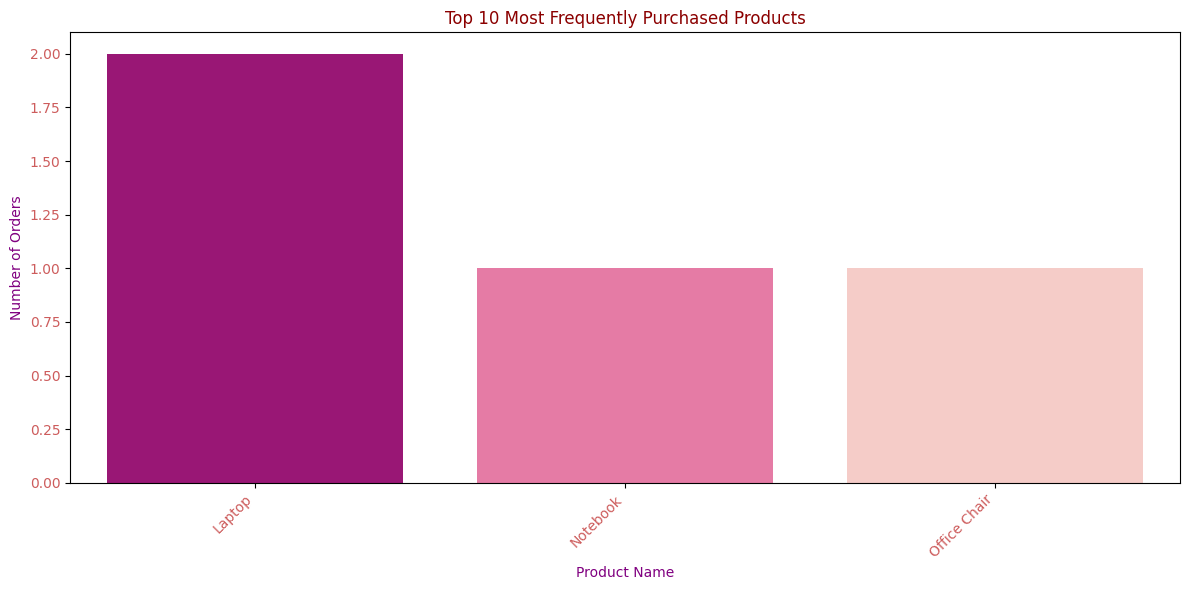

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the frequency of each product across all baskets using df_encoded
product_frequency = df_encoded.sum().sort_values(ascending=False)

# Get the top 10 most frequent products
top_10_products = product_frequency.head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_10_products.index, y=top_10_products.values, palette='RdPu_r') # Changed palette to a pink shade
plt.title('Top 10 Most Frequently Purchased Products', color='darkred') # Changed title color
plt.xlabel('Product Name', color='purple') # Changed xlabel color
plt.ylabel('Number of Orders', color='purple') # Changed ylabel color
plt.xticks(rotation=45, ha='right', color='indianred') # Changed xticks color
plt.yticks(color='indianred') # Changed yticks color
plt.tight_layout()
plt.show()

Data Visualization: Distribution of Items in Cart

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

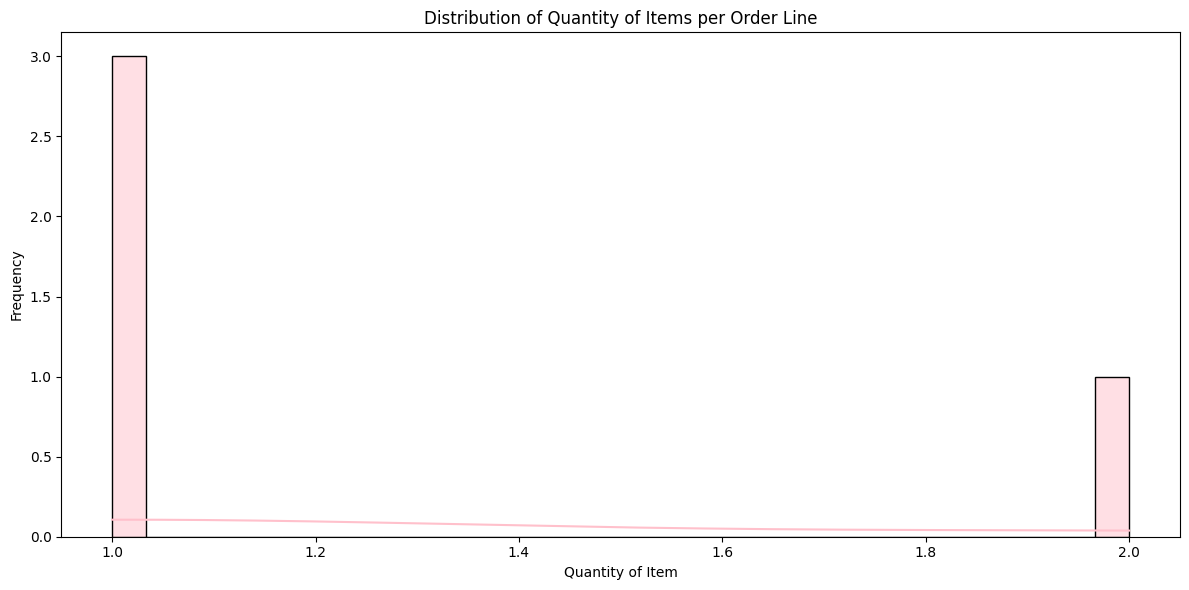

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [25]:
plt.figure(figsize=(12, 6))
sns.histplot(market_basket_df['quantity'], bins=30, kde=True, color='pink')
plt.title('Distribution of Quantity of Items per Order Line')
plt.xlabel('Quantity of Item')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

Calculate Average Number of Items per Order

In [26]:
average_items_per_order = data.groupby('order_id')['product_name'].count().mean()
print(f"Average number of items per order: {average_items_per_order:.2f}")

Average number of items per order: 1.33


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Data Visualization: Average Items per Order

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

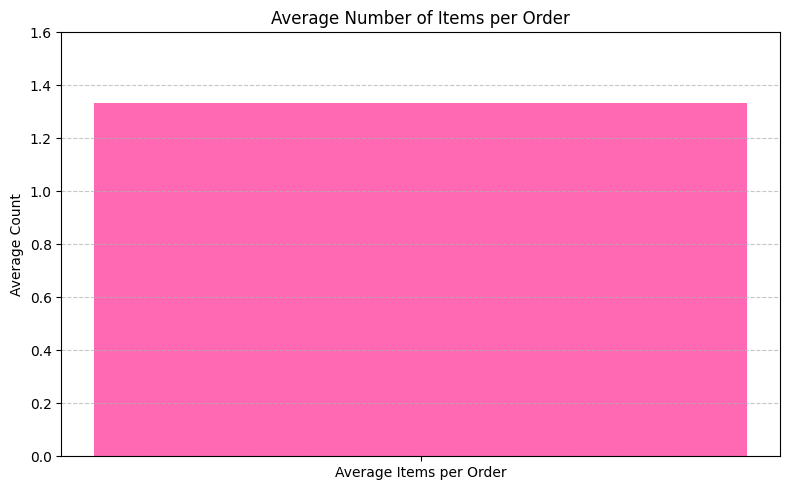

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [27]:
plt.figure(figsize=(8, 5))
plt.bar(['Average Items per Order'], [average_items_per_order], color='hotpink')
plt.title('Average Number of Items per Order')
plt.ylabel('Average Count')
plt.ylim(0, average_items_per_order * 1.2) # Set y-limit slightly above the value for better visualization
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**Apply K-Means Clustering**

In [28]:
from sklearn.cluster import KMeans
import pandas as pd
k_means_model = KMeans(n_clusters=2, random_state=42, n_init=10)


df_encoded['cluster'] = k_means_model.fit_predict(df_encoded)

print("df_encoded with cluster labels:")
display(df_encoded.head())

basket_with_clusters = basket.copy()
basket_with_clusters['cluster'] = df_encoded['cluster']
print("\nBasket DataFrame with cluster labels:")
display(basket_with_clusters.head())

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

df_encoded with cluster labels:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Laptop,Notebook,Office Chair,cluster
0,True,True,False,1
1,False,False,True,0
2,True,False,False,1



Basket DataFrame with cluster labels:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,order_id,items,cluster
0,1001,"[Laptop, Notebook]",1
1,1002,[Office Chair],0
2,1003,[Laptop],1


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Analyze Cluster Characteristics

Now let's examine the characteristics of each cluster by looking at the average presence of each product within that cluster. This will help us understand what makes each cluster distinct.

In [29]:
cluster_product_means = df_encoded.groupby('cluster').mean()

print("Average product presence per cluster:")
display(cluster_product_means.head())

# You can also look at the top products for each cluster
for i in range(k_means_model.n_clusters):
    print(f"\nTop products in Cluster {i}:")
    display(cluster_product_means.loc[i].sort_values(ascending=False).head())

Average product presence per cluster:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,Laptop,Notebook,Office Chair
cluster,,,
0,0.0,0.0,1.0
1,1.0,0.5,0.0



Top products in Cluster 0:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,0
Office Chair,1.0
Laptop,0.0
Notebook,0.0



Top products in Cluster 1:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,1
Laptop,1.0
Notebook,0.5
Office Chair,0.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Explanation of K-Means Clustering Results:**


*  K-Means Algorithm: K-Means is an unsupervised learning algorithm used to partition n observations into k clusters, where each observation belongs to the cluster with the nearest mean (centroid).
*  basket['cluster']: A new column has been added to your basket DataFrame, indicating which cluster each order belongs to.


*  cluster_product_means: This DataFrame shows the average presence (0 or 1) of each product within each cluster. A higher mean value indicates that the product is more frequently purchased by customers in that specific cluster.




This helps in understanding the typical "basket" for each customer segment.
To find the optimal number of clusters (K), you can use methods like the Elbow Method or Silhouette Score.

**Explanation of Agglomerative Hierarchical Clustering**

Agglomerative Hierarchical Clustering is a 'bottom-up' approach to clustering. It starts with each data point as its own cluster and then progressively merges pairs of clusters until all data points belong to a single cluster or a stopping criterion is met.

How it works:

1.Initialization: Each data point (in our case, each customer order represented in the basket DataFrame) is considered a single cluster.

2.Distance Calculation: The algorithm calculates the 'distance' or dissimilarity between all pairs of clusters. Common distance metrics for binary data like ours include Jaccard distance or Hamming distance.

3.Merging: The two closest clusters are merged into a new, larger cluster.

4.Iteration: Steps 2 and 3 are repeated until only one large cluster remains, or a predefined number of clusters is reached.

Key Concepts:

-Dendrogram: The merging process can be visualized as a tree-like diagram called a dendrogram. By cutting the dendrogram at a certain height, you can determine the number of clusters.

-Linkage Criteria: This determines how the distance between two clusters is calculated (e.g., single linkage - shortest distance between points in clusters, complete linkage - longest distance, average linkage - average distance, Ward's method - minimizes variance within clusters).

Advantages:

-Does not require specifying the number of clusters (K) beforehand, as the dendrogram allows for visual determination.


-Produces a hierarchy of clusters, which can be useful for understanding relationships at different levels of granularity.

Disadvantages:

-Can be computationally expensive for large datasets (O(n^3) complexity).

-Once a merge is made, it cannot be undone, which can sometimes lead to suboptimal clusters if early merges were poor.

Application in Instacart:
 Agglomerative clustering could help us identify a hierarchy of customer buying behaviors. For instance, we might find a broad cluster of 'healthy shoppers' which then branches into sub-clusters like 'organic produce buyers' and 'meat and dairy buyers'. This could be valuable for targeted marketing campaigns or store layout optimization.

**Apply DBSCAN (Density-Based Spatial Clustering of Applications with Noise)**


In [30]:
from sklearn.cluster import DBSCAN

# Prepare the input data for DBSCAN. Use df_encoded (one-hot encoded product presence).
# Drop the 'cluster' column if it exists from previous clustering attempts (e.g., K-Means)
data_for_dbscan = df_encoded.drop(columns=['cluster'], errors='ignore')


dbscan_model = DBSCAN(eps=0.5, min_samples=1) # Adjust eps and min_samples as needed

# Fit the model and predict clusters
basket['dbscan_cluster'] = dbscan_model.fit_predict(data_for_dbscan)

print("Basket with DBSCAN cluster labels:")
display(basket.head())

print("\nNumber of clusters found by DBSCAN (excluding noise, which is labeled -1):")
# The number of clusters is the count of unique labels excluding -1 (noise)
num_clusters = len(set(basket['dbscan_cluster'])) - (1 if -1 in basket['dbscan_cluster'].values else 0)
print(f"DBSCAN found {num_clusters} clusters and {list(basket['dbscan_cluster']).count(-1)} noise points.")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Basket with DBSCAN cluster labels:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,order_id,items,dbscan_cluster
0,1001,"[Laptop, Notebook]",0
1,1002,[Office Chair],1
2,1003,[Laptop],2


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


Number of clusters found by DBSCAN (excluding noise, which is labeled -1):
DBSCAN found 3 clusters and 0 noise points.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [31]:
print("Basket DataFrame with DBSCAN cluster assignments:")
display(basket[['dbscan_cluster']].head(3))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Basket DataFrame with DBSCAN cluster assignments:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,dbscan_cluster
0,0
1,1
2,2


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Data Visualization: DBSCAN Cluster Distribution

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

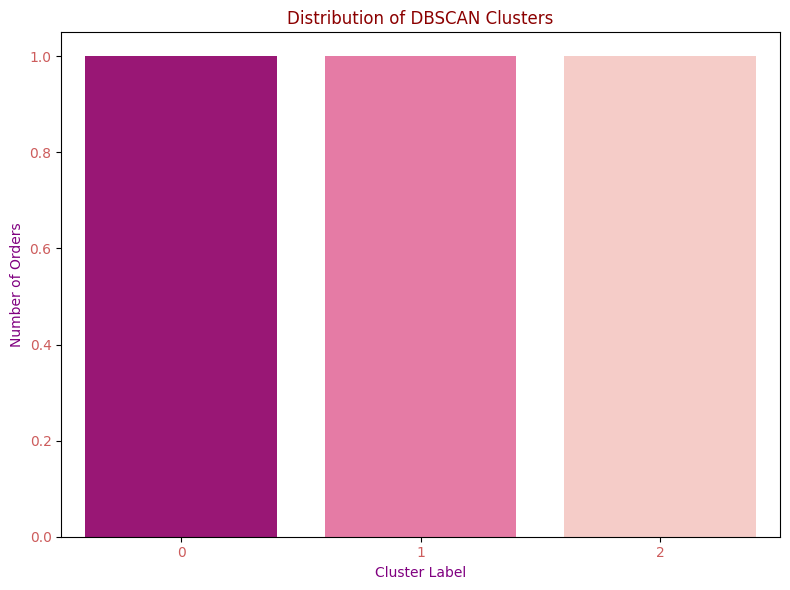

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.countplot(x='dbscan_cluster', data=basket, palette='RdPu_r') # Changed palette to a pink shade
plt.title('Distribution of DBSCAN Clusters', color='darkred') # Changed title color
plt.xlabel('Cluster Label', color='purple') # Changed xlabel color
plt.ylabel('Number of Orders', color='purple') # Changed ylabel color
plt.xticks(rotation=0, color='indianred') # Changed xticks color
plt.yticks(color='indianred') # Changed yticks color
plt.tight_layout()
plt.show()

**📦 Data Warehouse Project (Complete Structure)**




**DataWarehouse_Project**


├── **data**/

        ├── customers.csv
        ├── products.csv
        ├── orders.csv
        └── order_items.csv


├── **etl**/

       ├── extract.py
       ├── transform.py
       └── load.py

├── **database/**

     ├── create_tables.sql
     ├── insert_sample_data.sql
     └── analytics_queries.sql

├── diagrams/
  
     └── star_schema_diagram.png


├── **README.md**

     └── requirements.txt

**Sample Analytics Queries**



Total Sales


In [33]:
import sqlite3
import pandas as pd

# Connect to the sales_data database
conn = sqlite3.connect('sales_data.db')

# Execute the SQL query to sum total_amount from fact_sales
query = "SELECT SUM(total_amount) AS total_sales FROM fact_sales;"
total_sales_df = pd.read_sql_query(query, conn)

# Close the connection
conn.close()

print("Total Sales:")
display(total_sales_df)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Total Sales:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,total_sales
0,None


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Sales by Category

In [34]:
import sqlite3
import pandas as pd

# Connect to the sales_data database
conn = sqlite3.connect('sales_data.db')

# Execute the SQL query to find sales by category
query = """
SELECT
    dp.category,
    SUM(fs.total_amount) AS total_sales_by_category
FROM
    fact_sales fs
JOIN
    dim_product dp ON fs.product_id = dp.product_id
GROUP BY
    dp.category
ORDER BY
    total_sales_by_category DESC;
"""
sales_by_category_df = pd.read_sql_query(query, conn)

# Close the connection
conn.close()

print("Sales by Category:")
display(sales_by_category_df)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Sales by Category:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,category,total_sales_by_category


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Star Schema Diagram**

In [35]:
print("""
                        +----------------------+
                        |      DATA SOURCES    |
                        |----------------------|
                        | • CSV Files          |
                        | • Operational DB     |
                        | • External Systems   |
                        +----------+-----------+
                                   |
                                   v
                        +----------------------+
                        |       ETL PROCESS    |
                        |----------------------|
                        | Extract              |
                        | Transform            |
                        | Cleanse              |
                        | Load                 |
                        +----------+-----------+
                                   |
                                   v
                     +--------------------------------+
                     |        DATA WAREHOUSE          |
                     |        (STAR SCHEMA)           |
                     |--------------------------------|
                     |            FACT_SALES          |
                     |--------------------------------|
                     | customer_id (FK)               |
                     | product_id (FK)                |
                     | date_id (FK)                   |
                     | quantity                       |
                     | total_amount                   |
                     +-----+-----------+--------------+
                              |           |
                  -------------            ----------------
                  |                                       |
                  v                                       v
       +--------------------+                 +--------------------+
       |    DIM_CUSTOMER     |                 |     DIM_PRODUCT    |
       |--------------------|                 |--------------------|
       | customer_id (PK)   |                 | product_id (PK)    |
       | name               |                 | product_name       |
       | city               |                 | category           |
       | country            |                 | sub_category       |
       | segment            |                 | price              |
       +--------------------+                 +--------------------+
                                  |
                                  v
                        +--------------------+
                        |     DIM_DATE       |
                        |--------------------|
                        | date_id (PK)       |
                        | full_date          |
                        | day                |
                        | month              |
                        | year               |
                        +--------------------+

                                 |
                                 v
                        +----------------------+
                        |     ANALYTICS / BI   |
                        |----------------------|
                        | Reports              |
                        | Dashboards           |
                        | OLAP Analysis        |
                        | Data Mining          |
                        +----------------------+
""")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


                        +----------------------+
                        |      DATA SOURCES    |
                        |----------------------|
                        | • CSV Files          |
                        | • Operational DB     |
                        | • External Systems   |
                        +----------+-----------+
                                   |
                                   v
                        +----------------------+
                        |       ETL PROCESS    |
                        |----------------------|
                        | Extract              |
                        | Transform            |
                        | Cleanse              |
                        | Load                 |
                        +----------+-----------+
                                   |
                                   v
                     +--------------------------------+
                     |        DATA WAREHOUSE          |
    

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

 Tables Description


Fact Table: Sales_Fact

Stores numeric business measures (transaction data).

Purpose:
Contains measurable values used for analysis like revenue, profit, and sales volume.
| Column       | Description             |
| ------------ | ----------------------- |
| sales_id     | Primary Key             |
| customer_key | Customer Reference (FK) |
| product_id   | Product Reference (FK)  |
| time_id      | Time Reference (FK)     |
| total_amount | Total Sales Amount      |
| profit       | Profit Earned           |
| quantity     | Units Sold              |


Dimension Table: Time_Dim

Stores time-related information.

| Column  | Description |
| ------- | ----------- |
| time_id | Primary Key |
| date    | Full Date   |
| year    | Year Value  |
| month   | Month Value |
| day     | Day Value   |

Purpose:
Used for analyzing sales by day, month, quarter, or year.

Dimension Table: Product_Dim

Stores product details.

Purpose:
Used for analyzing sales by product type, category, and revenue.

| Column       | Description          |
| ------------ | -------------------- |
| product_id   | Primary Key          |
| product_name | Name of Product      |
| category     | Product Category     |
| sub_category | Product Sub-Category |
| price        | Product Price        |


Dimension Table: Customer_Dim

Stores customer information.

Purpose:
Used for analyzing sales by customer demographics and location.

| Column        | Description      |
| ------------- | ---------------- |
| customer_key  | Primary Key      |
| customer_name | Name of Customer |
| gender        | Gender           |
| city          | City             |
| country       | Country          |
| segment       | Customer Segment |


**Interactive  Sales Charts**

In [ ]:
import pandas as pd
import numpy as np
import plotly.express as px

# Sample Sales Data
np.random.seed(42)

data = pd.DataFrame({
    "Category": np.random.choice(
        ["Technology", "Furniture", "Office Supplies"], 200
    ),
    "Month": np.random.choice(
        ["Jan", "Feb", "Mar", "Apr", "May"], 200
    ),
    "Sales": np.random.randint(1000, 10000, 200)
})

# Define a consistent pink color scheme
pink_colors = ['deeppink', 'hotpink', 'palevioletred', 'lightpink', 'orchid']
title_color = 'darkred'
axis_label_color = 'purple'
tick_label_color = 'indianred'
paper_bg = 'pink'
plot_bg = 'lightpink'

# 1️⃣ Sales by Category (Interactive Bar Chart)
fig1 = px.bar(
    data.groupby("Category")["Sales"].sum().reset_index(),
    x="Category",
    y="Sales",
    title="Total Sales by Category",
    color_discrete_sequence=pink_colors
)
fig1.update_layout(title_font_color=title_color,
                   xaxis_title_font_color=axis_label_color, yaxis_title_font_color=axis_label_color,
                   paper_bgcolor=paper_bg, plot_bgcolor=plot_bg)
fig1.update_xaxes(tickfont_color=tick_label_color)
fig1.update_yaxes(tickfont_color=tick_label_color)
fig1.show()

# 2️⃣ Sales Trend by Month (Interactive Line Chart)
fig2 = px.line(
    data.groupby("Month")["Sales"].sum().reset_index(),
    x="Month",
    y="Sales",
    title="Sales Trend by Month",
    markers=True
)
fig2.update_traces(line=dict(color='deeppink')) # Explicitly set line color
fig2.update_layout(title_font_color=title_color,
                   xaxis_title_font_color=axis_label_color, yaxis_title_font_color=axis_label_color,
                   paper_bgcolor=paper_bg, plot_bgcolor=plot_bg)
fig2.update_xaxes(tickfont_color=tick_label_color)
fig2.update_yaxes(tickfont_color=tick_label_color)
fig2.show()

# 3️⃣ Sales Distribution (Interactive Pie Chart)
fig3 = px.pie(
    data.groupby("Category")["Sales"].sum().reset_index(),
    names="Category",
    values="Sales",
    title="Sales Distribution",
    color_discrete_sequence=pink_colors
)
fig3.update_layout(title_font_color=title_color,
                   paper_bgcolor=paper_bg, plot_bgcolor=plot_bg)
fig3.show()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**KPI Dashboard**


In [ ]:
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# --- Re-defining 'merged' DataFrame for robustness ---
import os

data_dir = "data"
# Ensure data files are loaded (assuming they exist at data_dir)
# If running from scratch, these might need to be loaded from source
# For this fix, we assume 'products' and 'order_items' are accessible
products = pd.read_csv(f"{data_dir}/products.csv")
order_items = pd.read_csv(f"{data_dir}/order_items.csv")

# Merge data as it was done previously
merged = order_items.merge(products, on="product_id")
merged["total_amount"] = merged["quantity"] * merged["price"]

# Handle missing values as it was done previously
merged = merged.dropna()
# --- End of 'merged' DataFrame re-definition ---


# Calculate KPIs from the 'merged' DataFrame
total_sales = merged['total_amount'].sum()
total_quantity_sold = merged['quantity'].sum()
average_order_value = merged['total_amount'].sum() / merged['order_id'].nunique()

# Create subplots for the dashboard
fig = make_subplots(rows=1, cols=3, specs=[[{'type':'indicator'}, {'type':'indicator'}, {'type':'indicator'}]])

# Add Total Sales KPI
fig.add_trace(go.Indicator(
    mode = "number",
    value = total_sales,
    title = {"text": "Total Sales", "font": {"color": "darkred"}},
    number={'prefix': "₹", "font": {"color": "deeppink"}}),
    row=1, col=1)

# Add Total Quantity Sold KPI
fig.add_trace(go.Indicator(
    mode = "number",
    value = total_quantity_sold,
    title = {"text": "Total Quantity Sold", "font": {"color": "darkred"}}),
    row=1, col=2)

# Add Average Order Value KPI
fig.add_trace(go.Indicator(
    mode = "number",
    value = average_order_value,
    title = {"text": "Average Order Value", "font": {"color": "darkred"}},
    number={'prefix': "₹", 'valueformat': '.2f', "font": {"color": "deeppink"}}),
    row=1, col=3)

fig.update_layout(title_text='<b style="color:darkred;">Sales KPI Dashboard</b>', title_x=0.5, title_font_size=24,
                  paper_bgcolor='pink', plot_bgcolor='lightpink')
fig.show()

**OLAP Operations**

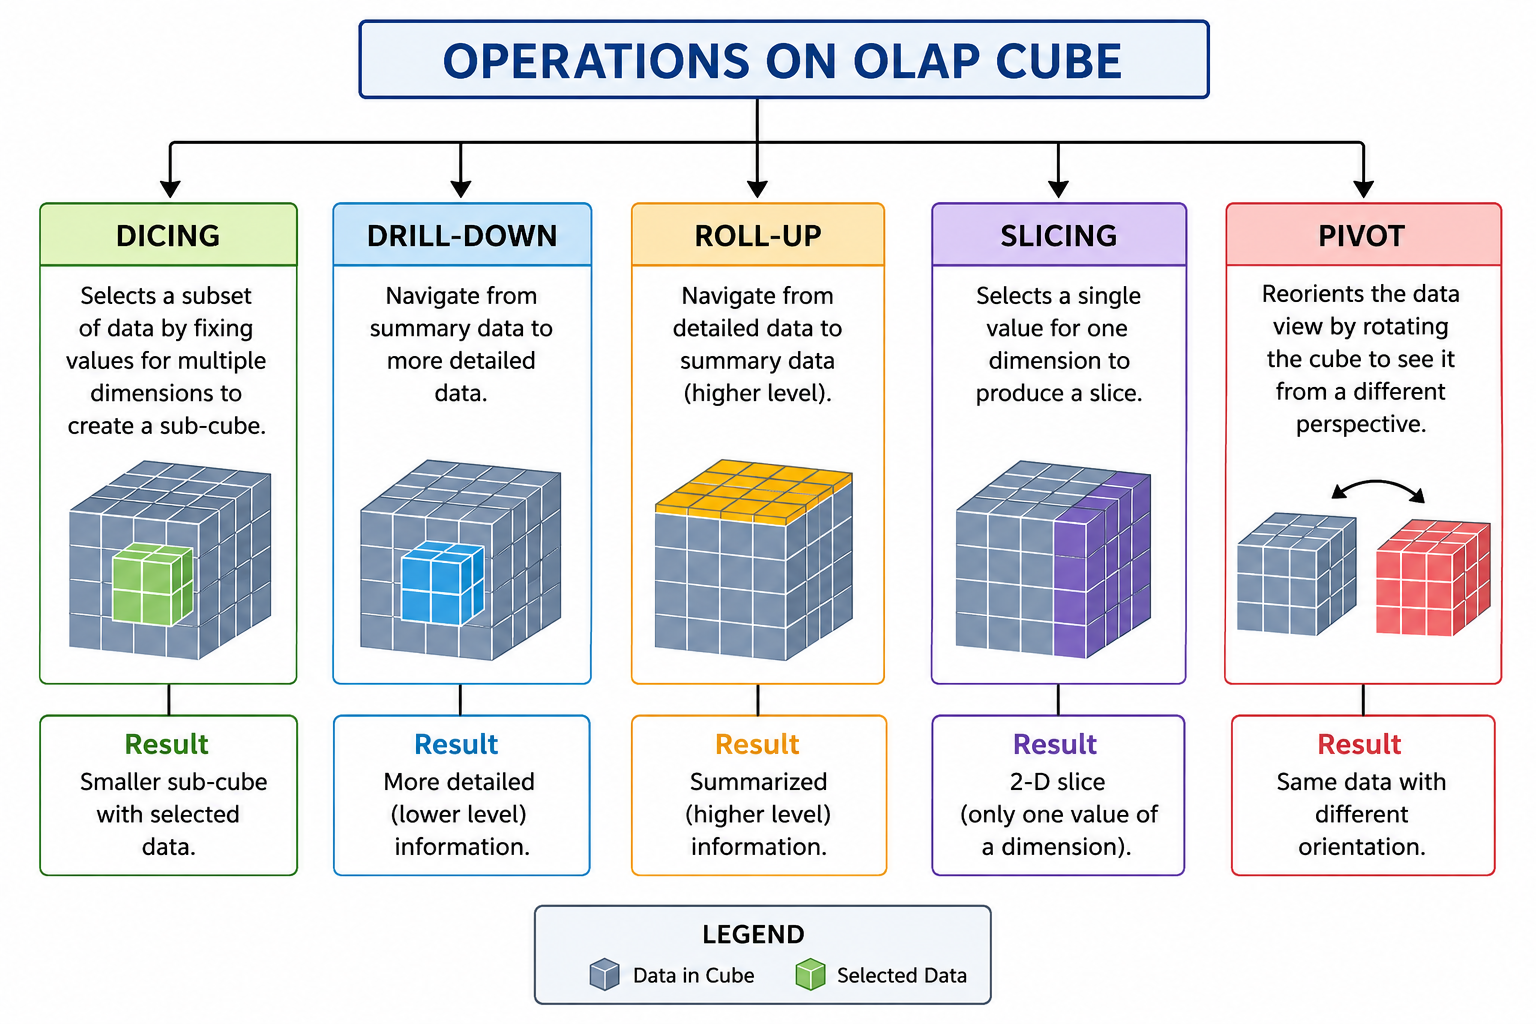

In [ ]:
import pandas as pd
import numpy as np

# -----------------------------
# Sample Data
# -----------------------------
np.random.seed(42)

data = pd.DataFrame({
    "order_date": pd.date_range(start="2025-01-01", periods=200, freq="D"),
    "product_category": np.random.choice(
        ["Technology", "Furniture", "Office Supplies"], 200
    ),
    "region": np.random.choice(
        ["North", "South", "East", "West"], 200
    ),
    "sales_amount": np.random.randint(1000, 10000, 200)
})

# Add Year and Month for OLAP
data["year"] = data["order_date"].dt.year
data["month"] = data["order_date"].dt.month

1️⃣Roll-Up (Summarization):Aggregates data to higher level.

Shows summerized data instead of deatiles data.

In [ ]:
# Roll-up 1: From Month to Year
# Aggregating sales_amount from a monthly level to a yearly level.
print("\n--- Roll-Up: Total Sales by Year ---")
sales_by_year = data.groupby('year')['sales_amount'].sum().reset_index()
display(sales_by_year)

# Roll-up 2: From Product Category to All Categories (Total Sales)
# Aggregating sales_amount from individual product categories to overall total sales.
print("\n--- Roll-Up: Total Sales Across All Product Categories ---")
total_sales_overall = data['sales_amount'].sum()
print(f"Total Sales Overall: {total_sales_overall:,.2f}")

# Roll-up 3: From Region to All Regions (Total Sales)
# Aggregating sales_amount from individual regions to overall total sales.
print("\n--- Roll-Up: Total Sales Across All Regions ---")
total_sales_region_overall = data['sales_amount'].sum()
print(f"Total Sales Overall (across regions): {total_sales_region_overall:,.2f}")

# Further roll-up: From (Year, Month, Category, Region) to (Year, Category)
print("\n--- Further Roll-Up: Total Sales by Year and Product Category ---")
sales_by_year_category = data.groupby(['year', 'product_category'])['sales_amount'].sum().reset_index()
display(sales_by_year_category)

### Data Visualization: Sales by Year and Product Category (Roll-Up)

In [ ]:
import plotly.express as px

# Define a consistent pink color scheme
pink_colors = ['deeppink', 'hotpink', 'palevioletred', 'lightpink', 'orchid']
title_color = 'darkred'
axis_label_color = 'purple'
tick_label_color = 'indianred'
paper_bg = 'pink'
plot_bg = 'lightpink'

fig_rollup_category = px.bar(
    sales_by_year_category,
    x="product_category",
    y="sales_amount",
    title="Total Sales by Product Category (Year 2025)",
    color="product_category",
    color_discrete_sequence=pink_colors
)
fig_rollup_category.update_layout(
    title_font_color=title_color,
    xaxis_title_font_color=axis_label_color, yaxis_title_font_color=axis_label_color,
    paper_bgcolor=paper_bg, plot_bgcolor=plot_bg
)
fig_rollup_category.update_xaxes(tickfont_color=tick_label_color)
fig_rollup_category.update_yaxes(tickfont_color=tick_label_color)
fig_rollup_category.show()

2️⃣ Drill-Down (Detailed View): Shows data in detail

Used for detailed analysis

In [ ]:
# 2️⃣ Drill-Down (Detailed View): Shows data in detail
# Drill-down from 'Total Sales by Product Category' to 'Total Sales by Month for a specific category'
print("--- Drill-Down: Monthly Sales for Technology Category (Year 2025) ---")
technology_sales_monthly = data[data['product_category'] == 'Technology'].groupby('month')['sales_amount'].sum().reset_index()
display(technology_sales_monthly)

# Further drill-down: From 'Monthly Sales for Technology' to 'Daily Sales for Technology in a specific month'
print("\n--- Further Drill-Down: Daily Sales for Technology in January 2025 ---")
technology_sales_january_daily = data[
    (data['product_category'] == 'Technology') &
    (data['year'] == 2025) &
    (data['month'] == 1)
][['order_date', 'sales_amount']].reset_index(drop=True)
display(technology_sales_january_daily)

### Data Visualization: Monthly Sales for Technology Category (Drill-Down)

In [ ]:
fig_tech_monthly = px.line(
    technology_sales_monthly,
    x="month",
    y="sales_amount",
    title="Monthly Sales for Technology Category (Year 2025)",
    markers=True
)
fig_tech_monthly.update_traces(line=dict(color='deeppink'))
fig_tech_monthly.update_layout(
    title_font_color=title_color,
    xaxis_title_font_color=axis_label_color, yaxis_title_font_color=axis_label_color,
    paper_bgcolor=paper_bg, plot_bgcolor=plot_bg
)
fig_tech_monthly.update_xaxes(tickfont_color=tick_label_color)
fig_tech_monthly.update_yaxes(tickfont_color=tick_label_color)
fig_tech_monthly.show()

3️⃣ Slice Operation: Selects a single dimension from the cube to create a new, 2D sub-cube .

In [ ]:
# 3️⃣ Slice Operation: Selects a single dimension from the cube to create a new, 2D sub-cube.

# Slice: Filter data to show sales for a specific product category (e.g., 'Technology')
print("--- Slice Operation: Sales for 'Technology' Product Category ---")
sales_technology_slice = data[data['product_category'] == 'Technology'].reset_index(drop=True)
display(sales_technology_slice.head())

print("\nShape of the original data:", data.shape)
print("Shape after slicing for 'Technology' category:", sales_technology_slice.shape)

# We can also get aggregated sales for this slice
print("\nTotal Sales for 'Technology' Category:", sales_technology_slice['sales_amount'].sum())

### Data Visualization: Sales for 'Technology' Category (Slice Operation)

In [ ]:
fig_slice_tech = px.line(
    sales_technology_slice,
    x="order_date",
    y="sales_amount",
    title="Daily Sales for 'Technology' Product Category",
    markers=True
)
fig_slice_tech.update_traces(line=dict(color='palevioletred')) # Use a pink shade
fig_slice_tech.update_layout(
    title_font_color=title_color,
    xaxis_title_font_color=axis_label_color, yaxis_title_font_color=axis_label_color,
    paper_bgcolor=paper_bg, plot_bgcolor=plot_bg
)
fig_slice_tech.update_xaxes(tickfont_color=tick_label_color)
fig_slice_tech.update_yaxes(tickfont_color=tick_label_color)
fig_slice_tech.show()

4️⃣ Dice Operation: Extracts a sub-cube by selecting multiple dimensions or a specific subset of data

In [ ]:
import pandas as pd

# Dice Operation: Selecting multiple dimensions (product_category, region) and a specific month (January)
print("--- Dice Operation: Sales for 'Technology' and 'Furniture' in 'North' and 'East' regions for January 2025 ---")
diced_data = data[
    (data['product_category'].isin(['Technology', 'Furniture'])) &
    (data['region'].isin(['North', 'East'])) &
    (data['month'] == 1)
].reset_index(drop=True)

display(diced_data.head())

print("\nShape of the original data:", data.shape)
print("Shape after dicing operation:", diced_data.shape)

# We can also get aggregated sales for this diced data
print("\nTotal Sales for Diced Data:", diced_data['sales_amount'].sum())

### Data Visualization: Sales for Diced Data (Product Category and Region)

In [ ]:
import plotly.express as px

# Aggregate diced data by product_category and region for visualization
diced_sales_agg = diced_data.groupby(['product_category', 'region'])['sales_amount'].sum().reset_index()

fig_dice_viz = px.bar(
    diced_sales_agg,
    x="product_category",
    y="sales_amount",
    color="region", # Color by region to see breakdown
    title="Total Sales for Diced Data by Product Category and Region",
    color_discrete_sequence=pink_colors,
    barmode='group' # Group bars for better comparison
)

fig_dice_viz.update_layout(
    title_font_color=title_color,
    xaxis_title_font_color=axis_label_color, yaxis_title_font_color=axis_label_color,
    paper_bgcolor=paper_bg, plot_bgcolor=plot_bg
)
fig_dice_viz.update_xaxes(tickfont_color=tick_label_color)
fig_dice_viz.update_yaxes(tickfont_color=tick_label_color)
fig_dice_viz.show()

5️⃣ Pivot (Switch/Rotate):  Reorients the data cube by rotating the axes to provide an alternative perspective (e.g., switching rows and columns to analyze data differently).

In [ ]:
import pandas as pd

# Pivot Operation: Reorienting the data to show sales by product category and region
print("--- Pivot Operation: Total Sales by Product Category and Region ---")
pivoted_data = pd.pivot_table(data, values='sales_amount', index='product_category', columns='region', aggfunc='sum', fill_value=0)
display(pivoted_data.head())

print("\nTotal Sales for each Product Category (from pivoted data):")
display(pivoted_data.sum(axis=1))

print("\nTotal Sales for each Region (from pivoted data):")
display(pivoted_data.sum(axis=0))

### Data Visualization: Total Sales by Product Category and Region (Pivot)

In [ ]:
import plotly.express as px

# Reset index to turn product_category into a regular column for plotting
pivoted_data_for_plot = pivoted_data.reset_index()

# Melt the DataFrame to have 'region' as a variable column for easy plotting
pivoted_data_melted = pivoted_data_for_plot.melt(id_vars='product_category', var_name='region', value_name='total_sales')

# Define a color map for regions, highlighting 'West'
region_color_map = {
    'East': pink_colors[0],
    'North': pink_colors[1],
    'South': pink_colors[2],
    'West': 'mediumvioletred' # A distinct pink shade for West
}

fig_pivot_viz = px.bar(
    pivoted_data_melted,
    x='product_category',
    y='total_sales',
    color='region', # Color by region
    title='Total Sales by Product Category and Region (Pivoted Data)',
    color_discrete_map=region_color_map, # Use the defined color map
    barmode='group' # Group bars for comparison
)

fig_pivot_viz.update_layout(
    title_font_color=title_color,
    xaxis_title_font_color=axis_label_color, yaxis_title_font_color=axis_label_color,
    paper_bgcolor=paper_bg, plot_bgcolor=plot_bg
)
fig_pivot_viz.update_xaxes(tickfont_color=tick_label_color)
fig_pivot_viz.update_yaxes(tickfont_color=tick_label_color)
fig_pivot_viz.show()